<a href="https://colab.research.google.com/github/soumyakumbar06/Machine-Learning-Lab-Exp/blob/main/4NI24CI107_Banknote_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("All libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)


All libraries imported successfully!
Scikit-learn version: 1.6.1



# MACHINE LEARNING MINI-PROJECT

## BANKNOTE AUTHENTICATION USING LOGISTIC REGRESSION

**Course:** Machine Learning

**Problem Type:** Binary Classification

**Algorithm:** Logistic Regression

**Dataset:** UCI Banknote Authentication Dataset

**Tool:** Google Colab


In [50]:

# Import pandas library
import pandas as pd

# Official UCI dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

# Define column names
column_names = [
    "Variance",
    "Skewness",
    "Curtosis",
    "Entropy",
    "Class"
]

# Load the dataset
df = pd.read_csv(
    url,
    header=None,
    names=column_names
)

# Display a success message
print("Dataset loaded successfully!")


Dataset loaded successfully!


In [51]:

# Display first 10 records
print("First 10 records:")
display(df.head(10))

# Display total number of rows and columns
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())


First 10 records:


,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.80730,-0.44699,0
1,4.54590,8.1674,-2.45860,-1.46210,0
2,3.86600,-2.6383,1.92420,0.10645,0
3,3.45660,9.5228,-4.01120,-3.59440,0
4,0.32924,-4.4552,4.57180,-0.98880,0
5,4.36840,9.6718,-3.96060,-3.16250,0
6,3.59120,3.0129,0.72888,0.56421,0
7,2.09220,-6.8100,8.46360,-0.60216,0
8,3.20320,5.7588,-0.75345,-0.61251,0
9,1.53560,9.1772,-2.27180,-0.73535,0



Dataset Shape:
(1372, 5)

Column Names:
['Variance', 'Skewness', 'Curtosis', 'Entropy', 'Class']


In [52]:

# Display dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [53]:

# Check missing values in each column

print("Missing Values:")

print(df.isnull().sum())


Missing Values:
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64


In [54]:

# Check duplicate records

duplicates = df.duplicated().sum()

print("Total duplicate records:", duplicates)


Total duplicate records: 24


In [55]:

# Check data types of all columns

print("Data Types:")

print(df.dtypes)


Data Types:
Variance    float64
Skewness    float64
Curtosis    float64
Entropy     float64
Class         int64
dtype: object


In [56]:

# Calculate descriptive statistics

print("Descriptive Statistics:")

display(df.describe())


Descriptive Statistics:


,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [57]:

# Count records in each class

class_counts = df["Class"].value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

# Calculate percentage

class_percentages = df["Class"].value_counts(
    normalize=True
).sort_index() * 100

print("\nClass Percentages:")
print(class_percentages)


Class Distribution:
Class
0    762
1    610
Name: count, dtype: int64

Class Percentages:
Class
0    55.539359
1    44.460641
Name: proportion, dtype: float64


In [58]:

# Check whether dataset is balanced

print("Class 0 percentage:",
      round(class_percentages[0], 2), "%")

print("Class 1 percentage:",
      round(class_percentages[1], 2), "%")


Class 0 percentage: 55.54 %
Class 1 percentage: 44.46 %


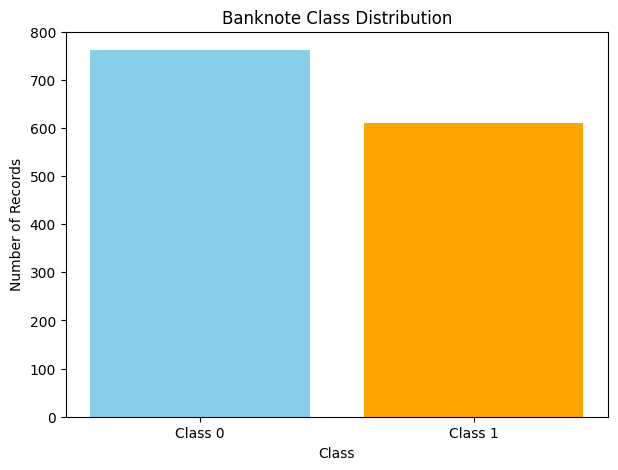

In [59]:

# Bar chart showing class distribution

class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.index.astype(str),
    class_counts.values,
    color=["skyblue", "orange"]
)

plt.title("Banknote Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Class 0", "Class 1"])

plt.show()


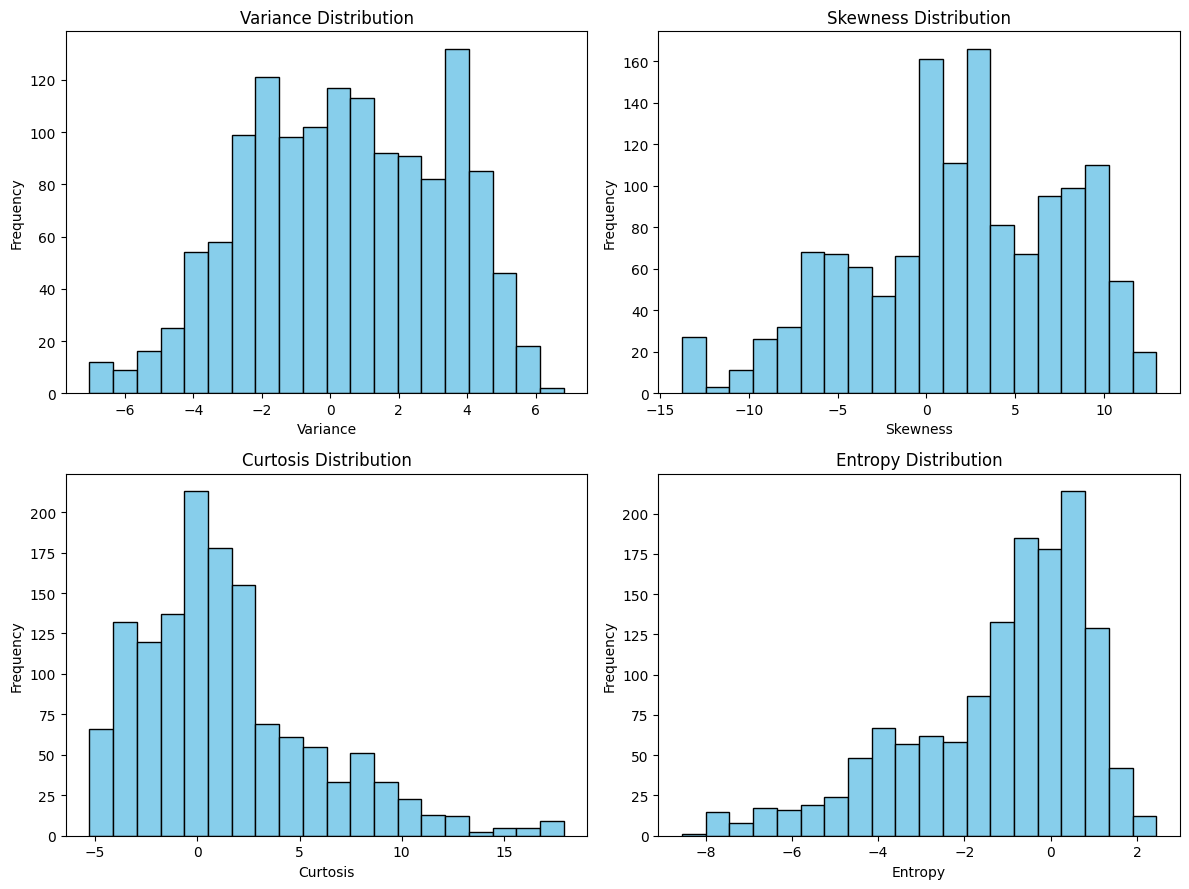

In [60]:

# Histograms of all four input features

features = [
    "Variance",
    "Skewness",
    "Curtosis",
    "Entropy"
]

plt.figure(figsize=(12, 9))

for i, feature in enumerate(features):
    plt.subplot(2, 2, i + 1)

    plt.hist(
        df[feature],
        bins=20,
        color="skyblue",
        edgecolor="black"
    )

    plt.title(feature + " Distribution")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


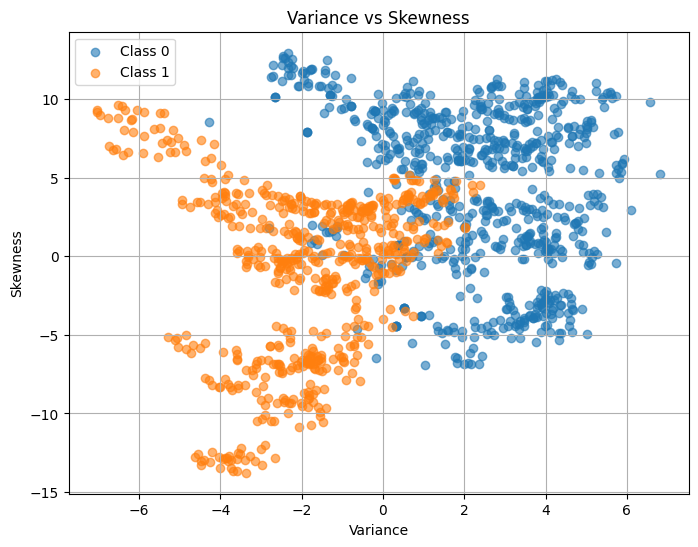

In [61]:

# Scatter plot: Variance vs Skewness

plt.figure(figsize=(8, 6))

for class_value in sorted(df["Class"].unique()):
    subset = df[df["Class"] == class_value]

    plt.scatter(
        subset["Variance"],
        subset["Skewness"],
        label=f"Class {class_value}",
        alpha=0.6
    )

plt.title("Variance vs Skewness")
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.legend()
plt.grid(True)

plt.show()


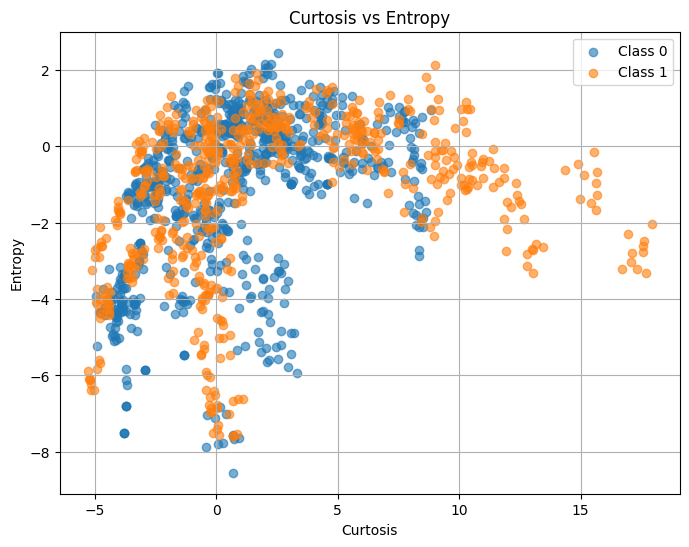

In [62]:

# Scatter plot: Curtosis vs Entropy

plt.figure(figsize=(8, 6))

for class_value in sorted(df["Class"].unique()):
    subset = df[df["Class"] == class_value]

    plt.scatter(
        subset["Curtosis"],
        subset["Entropy"],
        label=f"Class {class_value}",
        alpha=0.6
    )

plt.title("Curtosis vs Entropy")
plt.xlabel("Curtosis")
plt.ylabel("Entropy")
plt.legend()
plt.grid(True)

plt.show()


Observations from Data Visualisation
The bar chart shows that Class 0 has more records than Class 1, although the difference is not very large.
The histograms show that the four input features have different numerical distributions and ranges.
The Variance versus Skewness scatter plot shows differences in the distribution of the two classes, although some overlapping regions may be present.
The Curtosis versus Entropy scatter plot also shows differences between the classes. These features may help the classification model distinguish between the two categories.
No individual feature is guaranteed to classify every banknote correctly. Combining all four features may improve classification performance.

In [63]:

# Separate input features and target variable

X = df[[
    "Variance",
    "Skewness",
    "Curtosis",
    "Entropy"
]]

y = df["Class"]

# Display the number of features

print("Number of input features:", X.shape[1])

# Display shapes

print("Shape of X:", X.shape)

print("Shape of y:", y.shape)

# Display first five input records

display(X.head())

# Display first five target values

display(y.head())


Number of input features: 4
Shape of X: (1372, 4)
Shape of y: (1372,)


,Variance,Skewness,Curtosis,Entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880


,Class
0,0
1,0
2,0
3,0
4,0


In [64]:

# Import train_test_split

from sklearn.model_selection import train_test_split

print("Train-test split imported successfully!")


Train-test split imported successfully!


In [65]:

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")


Training and testing split completed!


In [66]:

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


Training features: (1097, 4)
Testing features: (275, 4)
Training labels: (1097,)
Testing labels: (275,)

Training records: 1097
Testing records: 275


In [67]:

from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")


StandardScaler imported successfully!


In [68]:

# Create StandardScaler object

scaler = StandardScaler()

# Fit and transform training data

X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")


Feature scaling completed successfully!


In [69]:

print("Scaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Testing Data:")
print(X_test_scaled[:5])

print("\nTraining data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Scaled Training Data:
[[ 0.39687699  0.05746643 -1.03953765  0.51951506]
 [-0.38173115 -0.22255311 -0.41215984  0.26034815]
 [ 1.25707446 -0.2779253  -0.11902626  1.13526037]
 [-0.10891208 -0.29720014 -0.70982581  0.85710298]
 [-1.1841959  -0.41950842  0.27444212  1.22779629]]

Scaled Testing Data:
[[ 0.67206974  0.95146612 -0.31989126 -0.25003035]
 [-0.6719866   0.04589915 -0.4320298  -0.21511024]
 [-0.4403584   1.30297244 -1.1930052  -2.98014804]
 [-0.30693183 -0.2253577  -0.4446213   0.88712385]
 [-0.90146651 -1.52062841  1.19614286  0.41535648]]

Training data shape: (1097, 4)
Testing data shape: (275, 4)


Observation on Feature Scaling

StandardScaler was used to standardise the four input features. The scaler was fitted only on the training dataset and then used to transform both training and testing datasets.

Feature scaling helps Logistic Regression by placing numerical features on comparable scales. This also prevents data leakage because the testing data was not used to calculate the scaling parameters.

In [70]:

# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")


Logistic Regression imported successfully!


In [71]:

# Create Logistic Regression model

model = LogisticRegression(max_iter=1000)

print("Logistic Regression model created successfully!")


Logistic Regression model created successfully!


In [72]:

# Train the Logistic Regression model

model.fit(X_train_scaled, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [73]:

print("Model Parameters:")
print(model.get_params())


Model Parameters:
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [74]:

# Predict the test data

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 15 predicted classes:")
print(y_pred[:15])


Predictions generated successfully!

First 15 predicted classes:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0]


In [75]:

# Compare actual and predicted classes

comparison = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred
})

display(comparison.head(15))


,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,1,1
6,0,0
7,0,0
8,0,0
9,1,1


In [76]:

# Calculate class probabilities

y_prob = model.predict_proba(X_test_scaled)

# Display first 10 probability results

probability_results = pd.DataFrame({
    "Actual Class": y_test.values[:10],
    "Predicted Class": y_pred[:10],
    "Probability Class 0": y_prob[:10, 0],
    "Probability Class 1": y_prob[:10, 1]
})

display(probability_results)


,Actual Class,Predicted Class,Probability Class 0,Probability Class 1
0,0,0,0.999576,0.000424
1,1,1,0.033572,0.966428
2,0,0,0.755631,0.244369
3,1,1,0.035568,0.964432
4,1,1,0.006959,0.993041
5,1,1,0.259981,0.740019
6,0,0,0.999274,0.000726
7,0,0,0.999799,0.000201
8,0,0,0.996741,0.003259
9,1,1,0.077905,0.922095


In [77]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Evaluation metrics imported successfully!")


Evaluation metrics imported successfully!


In [78]:

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label=1)

recall = recall_score(y_test, y_pred, pos_label=1)

f1 = f1_score(y_test, y_pred, pos_label=1)

print("Model Evaluation Results")

print("Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))


Model Evaluation Results
Accuracy: 0.9709
Accuracy Percentage: 97.09 %
Precision: 0.9385
Recall: 1.0
F1 Score: 0.9683


In [79]:

print("Complete Classification Report:")

print(classification_report(y_test, y_pred))


Complete Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275



In [80]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[145   8]
 [  0 122]]


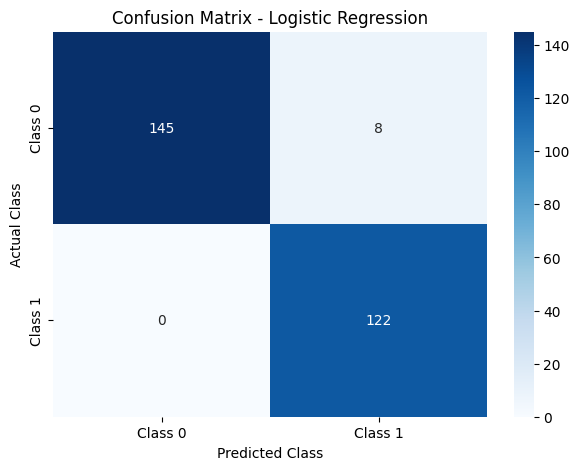

In [81]:

import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()


In [82]:

TN, FP, FN, TP = cm.ravel()

print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)


True Negative (TN): 145
False Positive (FP): 8
False Negative (FN): 0
True Positive (TP): 122


In [83]:

thresholds = [0.30, 0.50, 0.70]

threshold_results = []

for threshold in thresholds:

    # Predict Class 1 when probability >= threshold
    threshold_pred = (
        y_prob[:, 1] >= threshold
    ).astype(int)

    # Calculate metrics
    acc = accuracy_score(y_test, threshold_pred)

    prec = precision_score(
        y_test, threshold_pred,
        pos_label=1, zero_division=0
    )

    rec = recall_score(
        y_test, threshold_pred,
        pos_label=1, zero_division=0
    )

    f1 = f1_score(
        y_test, threshold_pred,
        pos_label=1, zero_division=0
    )

    cm_threshold = confusion_matrix(
        y_test, threshold_pred,
        labels=[0, 1]
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "Confusion Matrix": cm_threshold.tolist()
    })

# Display comparison table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)


,Threshold,Accuracy,Precision,Recall,F1 Score,Confusion Matrix
0,0.3,0.970909,0.938462,1.0,0.968254,"[[145, 8], [0, 122]]"
1,0.5,0.970909,0.938462,1.0,0.968254,"[[145, 8], [0, 122]]"
2,0.7,0.996364,0.991870,1.0,0.995918,"[[152, 1], [0, 122]]"


In [84]:

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [85]:

# Predict the testing data

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("First 15 predictions:")
print(y_pred[:15])


Predictions generated successfully!
First 15 predictions:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0]


In [86]:

comparison = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred
})

display(comparison.head(15))


,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,1,1
6,0,0
7,0,0
8,0,0
9,1,1


In [87]:

# Generate probabilities for both classes

y_prob = model.predict_proba(X_test_scaled)

probability_results = pd.DataFrame({
    "Actual Class": y_test.values[:10],
    "Predicted Class": y_pred[:10],
    "Probability Class 0": y_prob[:10, 0],
    "Probability Class 1": y_prob[:10, 1]
})

display(probability_results)


,Actual Class,Predicted Class,Probability Class 0,Probability Class 1
0,0,0,0.999576,0.000424
1,1,1,0.033572,0.966428
2,0,0,0.755631,0.244369
3,1,1,0.035568,0.964432
4,1,1,0.006959,0.993041
5,1,1,0.259981,0.740019
6,0,0,0.999274,0.000726
7,0,0,0.999799,0.000201
8,0,0,0.996741,0.003259
9,1,1,0.077905,0.922095


Observations on Model Predictions

The Logistic Regression model was trained using the scaled training dataset. The trained model was used to predict the class labels of the testing dataset.

Predicted probabilities were also generated for Class 0 and Class 1. These probabilities indicate the model's estimated confidence in each class prediction.

The actual and predicted labels were compared to identify correct and incorrect predictions.

In [88]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Evaluation libraries imported successfully!")


Evaluation libraries imported successfully!


In [89]:

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label=1
)

recall = recall_score(
    y_test, y_pred, pos_label=1
)

f1 = f1_score(
    y_test, y_pred, pos_label=1
)

# Display results

print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))


MODEL EVALUATION RESULTS
------------------------
Accuracy: 0.9709
Accuracy Percentage: 97.09 %
Precision: 0.9385
Recall: 1.0
F1 Score: 0.9683


In [90]:

print("COMPLETE CLASSIFICATION REPORT")
print("--------------------------------")

print(classification_report(y_test, y_pred))


COMPLETE CLASSIFICATION REPORT
--------------------------------
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275



Interpretation of Evaluation Metrics

Accuracy measures the overall proportion of correct predictions. However, accuracy alone does not explain the types of classification errors made by the model.

Precision measures how reliable the positive predictions are, while recall measures how many actual positive records are correctly identified. The F1-score combines precision and recall into a single measure.

Therefore, all four metrics are important when evaluating a binary classification model.

In [91]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[145   8]
 [  0 122]]


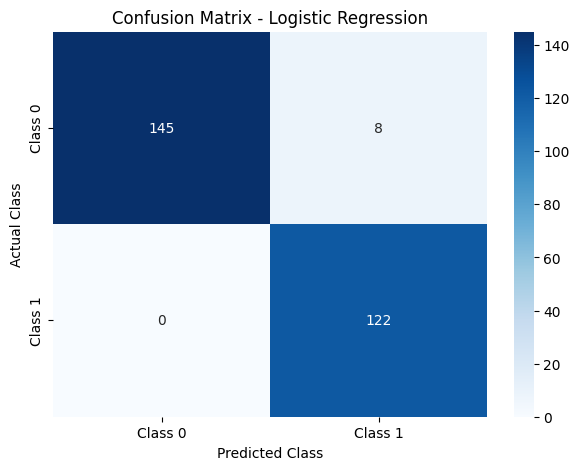

In [92]:

import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()


In [93]:

TN, FP, FN, TP = cm.ravel()

print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)


True Negative (TN): 145
False Positive (FP): 8
False Negative (FN): 0
True Positive (TP): 122


In [94]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Define thresholds
thresholds = [0.30, 0.50, 0.70]

results = []

for threshold in thresholds:

    # Generate predictions using threshold
    threshold_pred = (
        y_prob[:, 1] >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, threshold_pred)

    precision = precision_score(
        y_test, threshold_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test, threshold_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test, threshold_pred,
        zero_division=0
    )

    # Generate confusion matrix
    cm_threshold = confusion_matrix(
        y_test,
        threshold_pred,
        labels=[0, 1]
    )

    # Store results
    results.append({
        "Threshold": threshold,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4),
        "Confusion Matrix": cm_threshold.tolist()
    })

# Display comparison
threshold_df = pd.DataFrame(results)

display(threshold_df)


,Threshold,Accuracy,Precision,Recall,F1 Score,Confusion Matrix
0,0.3,0.9709,0.9385,1.0,0.9683,"[[145, 8], [0, 122]]"
1,0.5,0.9709,0.9385,1.0,0.9683,"[[145, 8], [0, 122]]"
2,0.7,0.9964,0.9919,1.0,0.9959,"[[152, 1], [0, 122]]"


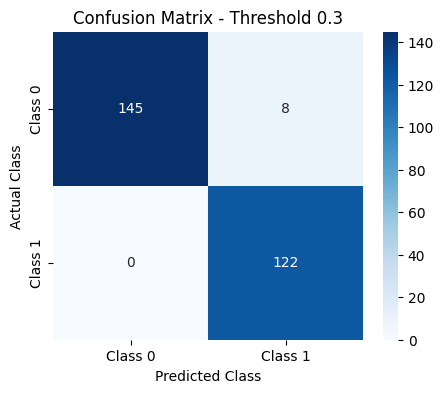

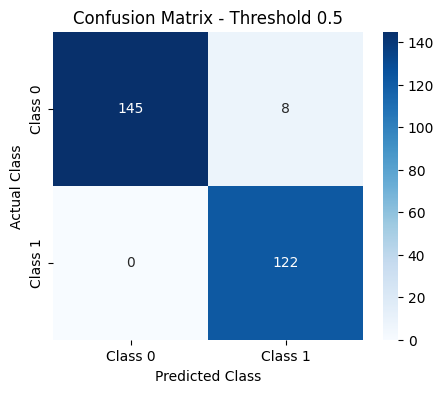

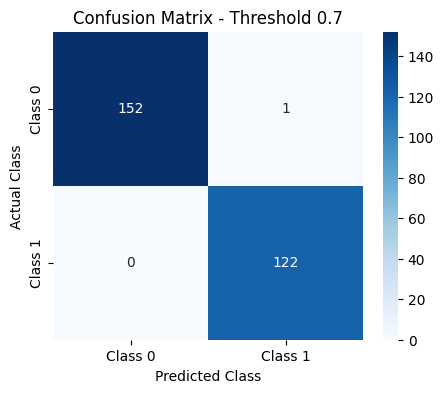

In [95]:

for threshold in thresholds:

    threshold_pred = (
        y_prob[:, 1] >= threshold
    ).astype(int)

    cm_threshold = confusion_matrix(
        y_test,
        threshold_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm_threshold,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Class 0", "Class 1"],
        yticklabels=["Class 0", "Class 1"]
    )

    plt.title(
        f"Confusion Matrix - Threshold {threshold}"
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.show()


Threshold Comparison – Observations

Three classification thresholds, 0.30, 0.50 and 0.70, were investigated using the predicted probabilities from the Logistic Regression model.

At a threshold of 0.30, the model uses a lower probability requirement for predicting Class 1. This can increase the number of positive predictions and may improve recall.

At a threshold of 0.50, the model uses the standard classification threshold.

At a threshold of 0.70, the model requires a higher probability before predicting Class 1. This can reduce positive predictions and may improve precision.

Changing the threshold affects the balance between precision and recall. The most suitable threshold depends on the cost of false positive and false negative errors.

Conclusion

This mini-project focused on Banknote Authentication using Logistic Regression, a supervised Machine Learning algorithm for binary classification. The UCI Banknote Authentication dataset containing 1,372 records and four numerical input features, namely Variance, Skewness, Curtosis and Entropy, was used to develop the classification model.

The dataset was explored to understand its structure, class distribution, missing values and duplicate records. Data visualisations were created using bar charts, histograms and scatter plots. The dataset was divided into 80% training data and 20% testing data using stratified splitting. StandardScaler was applied to standardise the features without causing data leakage.

The Logistic Regression model was trained successfully and used to predict class labels and probabilities. Its performance was evaluated using accuracy, precision, recall, F1-score and a confusion matrix. Different classification thresholds of 0.30, 0.50 and 0.70 were also investigated to understand their effects on model predictions.

Recall is particularly important when failing to identify forged banknotes is costly, provided the forged-note class is correctly identified. However, the dataset's limited scope and the model's possible limitations mean that it should not be used for real banking authentication decisions.

Overall, this project provided practical knowledge of data preprocessing, classification, model evaluation and threshold selection.

In [96]:

print("===== FINAL PROJECT SUMMARY =====")

print("Dataset shape:", df.shape)
print("Duplicate records:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nThreshold Comparison:")
display(threshold_df)


===== FINAL PROJECT SUMMARY =====
Dataset shape: (1372, 5)
Duplicate records: 24
Missing values: 0

Training records: 1097
Testing records: 275

Accuracy: 0.9709
Precision: 0.9385
Recall: 1.0
F1 Score: 0.9683

Confusion Matrix:
[[145   8]
 [  0 122]]

Threshold Comparison:


,Threshold,Accuracy,Precision,Recall,F1 Score,Confusion Matrix
0,0.3,0.9709,0.9385,1.0,0.9683,"[[145, 8], [0, 122]]"
1,0.5,0.9709,0.9385,1.0,0.9683,"[[145, 8], [0, 122]]"
2,0.7,0.9964,0.9919,1.0,0.9959,"[[152, 1], [0, 122]]"
